# Практическая работа №1: Основы анализа и моделирования социальных сетей

Выполнил студент гр. 4385 Чечулин Денис Сергеевич. Вариант №2.

## Цель работы

Овладеть навыками работы с математическими пакетами для моделирования, визуализации и анализа социальных сетей.

## Постановка задачи

С помощью математических пакетов и соответствующих библиотек провести анализ заданных социальных сетей, вычислить описательные характеристики. Полученные результаты содержательно проинтерпретировать.

## Основные теоретические положения

**Актор** — базовый элемент, представляющий отдельную единицу, участвующую во взаимодействии.

**Реляционная связь** — отношение взаимодействия или ассоциации между двумя акторами в сети.

**Диада** — базовая структура социальной сети. Два актора и связь между ними.

**Триада** — подструктура сети, состоит из трех акторов и всех потенциальных связей между ними.

**Группа** — подмножество акторов в сети, объединенное каким-либо общим признаком, отношением, взаимодействием.

**Подгруппа** — это подмножество акторов внутри группы или сети, обладающее определенными уникальными свойствами взаимодействия.

**Социальная сеть** — объект, представляющий собой совокупность конечного набора акторов и отношений, определенных на них.

**Модальность** — характеристика, определяющая количество типов акторов в сети. Бывают одномодальные сети (все узлы принадлежат одному типу) и т.д.

**Способы представления сетей:**
1. Графовое
2. Социальное
3. Алгебраическое

**Пятичисловая сводка для анализа сетей:**

1. Размер сети — количество акторов в сети.
2. Плотность сети — доля имеющихся связей по отношению к максимально возможному количеству связей.

$$ den(G) = \frac{\sum_{i = 1}^g \sum_{j = 1}^g x_{ij}}{g(g-1)} $$

3. Компонента связности.
4. Диаметр сети.
5. Глобальный коэффициент кластеризации — мера, характеризующая степень кластеризации (треугольности) всей сети в целом.

$$ d_t(G) = \frac{3\tau_{\triangle}(u)}{\tau_3(G)} $$

где $\tau_{\triangle}$ — количество треугольников, в которых в триаде наблюдаются ровно три связи;
где $\tau_3$ — количество треугольников, в которых наблюдается 2 или 3 связи.

**Локальный коэффициент кластеризации** — мера, которая характеризует степень кластеризации треугольника для конкретного узла в сети.

$$
cl(n_i) =
\begin{cases}
\frac{2N_i}{k_i(k_i - 1)}, & k_i \geq 2 \\
0, & k_i < 2
\end{cases}
$$

*   $k_i$ — число смежных с \(i\) узлов;
*   $N_i$ — количество ребер, связывающих смежные узлы между собой.

**Центральность** — количественная мера $C_A$, определяет относительную важность актора или его влияние в сети на основе его позиции и связей с другими акторами.

* **Центральность по степени:**
* $C_D(n_i) = deg(n_i)$
* **Нормированная центральность по степени:**
* $C_D'(n_i) = \frac{deg(n_i)}{g - 1}$
* **Центральность по близости:**
* $C_C(n_i) = (\sum_{j = 1}^g d(n_i, n_j))^{-1}$
* **Центральность по посредничеству:**
* $C_B(n_i) = \sum_{i \subset K} \frac{\sigma_{ik}(n_i)}{\sigma_{ik}}$
* **Центральность по информации:**
* $C_I(n_i) = \frac{1}{c_{ii} + (T - 2R)/g}$

**Престиж** — количественная мера $P_A$ влиятельности актора, основанная на входных связях.

* **Престиж по степени:**
* $P_D(n_i) = deg_I(n_i)$
* **Престиж по близости:**
* $P_P(n_i) = \frac{|I_i| / (g - 1)}{\sum_{n_j \in I_i} d(n_j, n_i) / |I_i|}$
* **Престиж по рангу:** вычисляется через решение системы уравнений
* $p = X^Tp$, где $X$ — социоматрица.

## Выполнение работы

**Задание 1.** Из файла `florentine_marital.csv` извлечь социоматрицу с помощью соответствующих функций. Вывести полученную социоматрицу на экран.

In [18]:
# Прочтение CSV-файла
network_raw <- read.csv("florentine_marital.csv", comment.char = "#", header = TRUE)

# Преобразование датафрейма в матрицу
network_matrix <- as.matrix(network_raw)

# Вывод матрицы на экран
print(network_matrix)

      Acciaiuoli Albizzi Barbadori Bischeri Castellani Ginori Guadagni
 [1,]          0       0         0        0          0      0        0
 [2,]          0       0         0        0          0      1        1
 [3,]          0       0         0        0          1      0        0
 [4,]          0       0         0        0          0      0        1
 [5,]          0       0         1        0          0      0        0
 [6,]          0       1         0        0          0      0        0
 [7,]          0       1         0        1          0      0        0
 [8,]          0       0         0        0          0      0        1
 [9,]          1       1         1        0          0      0        0
[10,]          0       0         0        0          0      0        0
[11,]          0       0         0        1          1      0        0
[12,]          0       0         0        0          0      0        0
[13,]          0       0         0        0          0      0        0
[14,] 

**Задание 2.** Преобразовать социоматрицу в список рёбер. Вывести первые 5 элементов списка рёбер.

Сначала мы находим позиции всех ячеек, где значение не равно нулю (то есть где есть связь). Функция `which(..., arr.ind = TRUE)` возвращает не просто номера, а пары координат: (строка, столбец). Затем мы создаем датафрейм, где первый столбец — это «откуда» (`from`), а второй — «куда» (`to`).

In [20]:
# Находждение индексов всех ненулевых элементов в матрице
idx <- which(network_matrix != 0, arr.ind = TRUE)

# Преобразование в датафрейм (список рёбер) и вывод первых 5 строк
network_edgelist <- data.frame(from = idx[, 1], to = idx[, 2])
print(head(network_edgelist, 5))

  from to
1    9  1
2    6  2
3    7  2
4    9  2
5    5  3


**Задание 3.** Присвоить имена столбцам и строкам социоматрицы.

Имена столбцов уже были извлечены из первой строки файла благодаря параметру `header = TRUE`. Теперь скопируем эти имена в атрибут строк матрицы, чтобы у нас была полная разметка.

In [19]:
# Присваивание имен строк именам столбцов
rownames(network_matrix) <- colnames(network_matrix)
print(network_matrix)

             Acciaiuoli Albizzi Barbadori Bischeri Castellani Ginori Guadagni
Acciaiuoli            0       0         0        0          0      0        0
Albizzi               0       0         0        0          0      1        1
Barbadori             0       0         0        0          1      0        0
Bischeri              0       0         0        0          0      0        1
Castellani            0       0         1        0          0      0        0
Ginori                0       1         0        0          0      0        0
Guadagni              0       1         0        1          0      0        0
Lamberteschi          0       0         0        0          0      0        1
Medici                1       1         1        0          0      0        0
Pazzi                 0       0         0        0          0      0        0
Peruzzi               0       0         0        1          1      0        0
Pucci                 0       0         0        0          0   

**Задание 4.** С помощью соответствующих функций по полученной социоматрице построить ненаправленную сеть. Объяснить параметры, передаваемые в функцию.

Для работы с сетями мы подключим библиотеки `network` (для создания объекта сети) и `sna` (для её анализа и визуализации).

 Network attributes:
  vertices = 16 
  directed = FALSE 
  hyper = FALSE 
  loops = FALSE 
  multiple = FALSE 
  bipartite = FALSE 
  total edges= 20 
    missing edges= 0 
    non-missing edges= 20 

 Vertex attribute names: 
    vertex.names 

No edge attributes


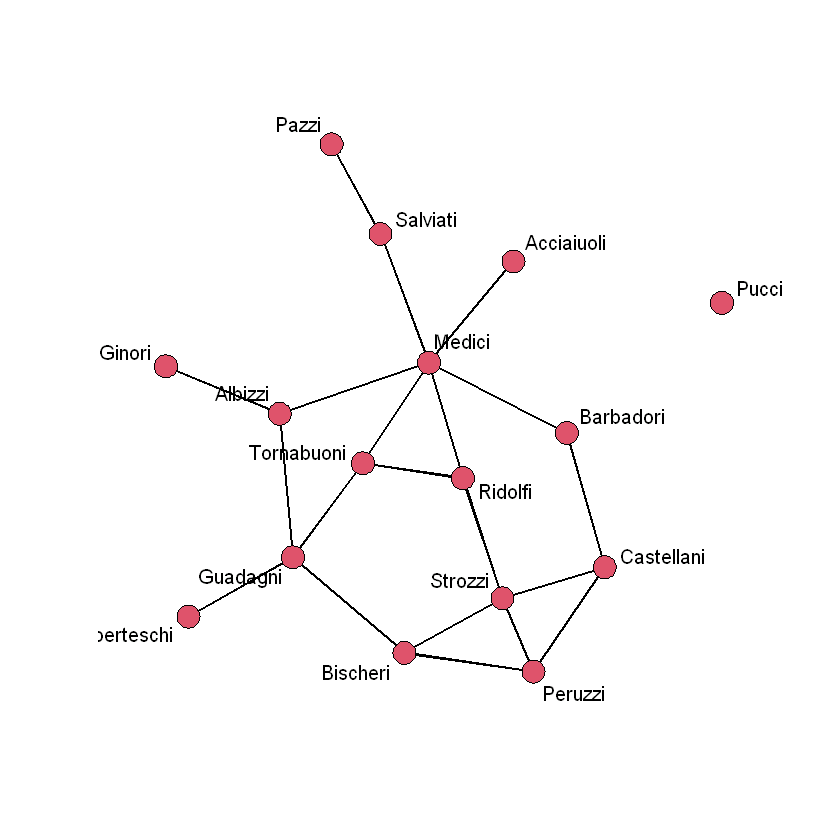

In [17]:
# Подключение библиотек
library(network)
library(sna)

# Создание объекта сети и вывод сводки о ней
net <- network(network_matrix, directed = FALSE, matrix.type = "adjacency", ignore.eval = TRUE)
print(net)

# График сети
gplot(net, gmode = "graph", displaylabels = TRUE)

**Объяснение параметров функции `network()`:**
*   `network_matrix` — сама социоматрица, которую мы подготовили.
*   `directed = FALSE` — указывает, что сеть ненаправленная (связи двусторонние, матрица симметрична).
*   `matrix.type = "adjacency"` — подсказывает функции, что на вход подаётся матрица смежности (где на пересечении строк и столбцов стоят 1 и 0), а не список рёбер.
*   `ignore.eval = TRUE` — говорит игнорировать веса (значения в ячейках). Нам важно только наличие связи (есть она или нет), а не её сила.

**Параметры функции `gplot()`:**
*   `net` — объект сети, который мы построили.
*   `gmode = "graph"` — режим визуализации для ненаправленного графа.
*   `displaylabels = TRUE` — указывает, что нужно подписывать вершины (именами семей).

**Задание 5.** Отобразить сеть с помощью алгоритмов укладки Фрюхтермана—Рейнгольда и Камада—Каваи. Объяснить, в чём различие между алгоритмами и укладками.

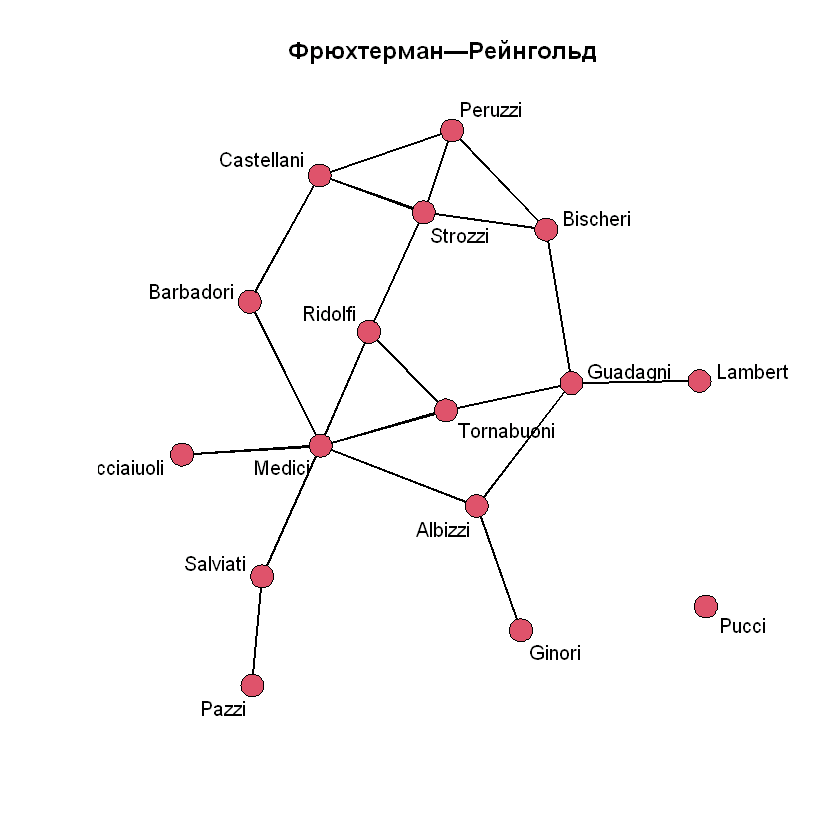

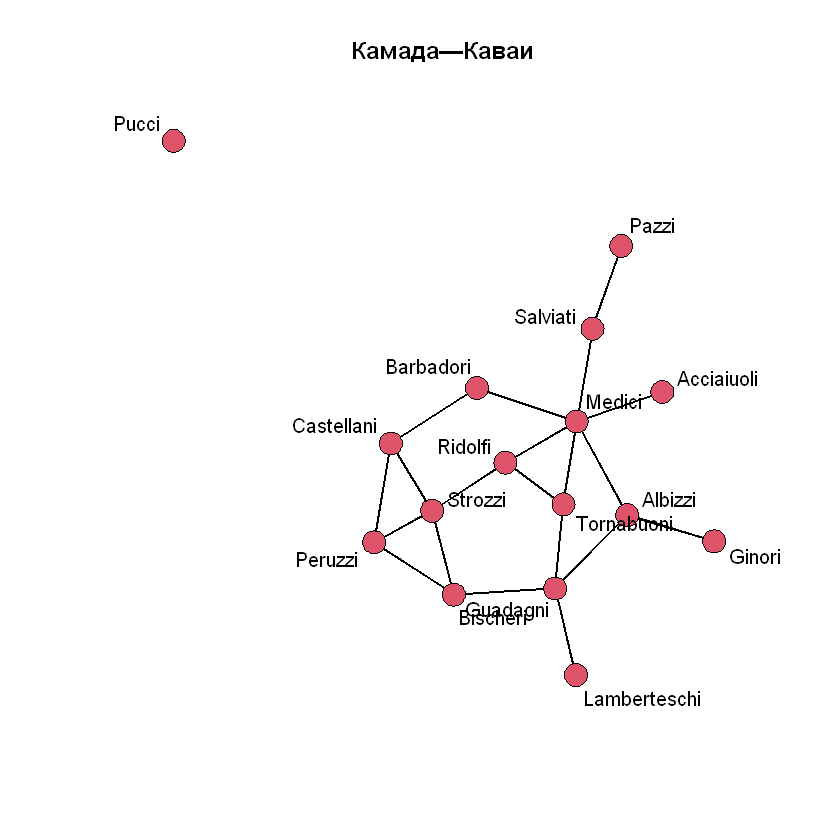

In [22]:
# Укладка Фрюхтермана—Рейнгольда
gplot(net, gmode = "graph", mode = "fruchtermanreingold", displaylabels = TRUE, main = "Фрюхтерман—Рейнгольд")

# Укладка Камада—Каваи
gplot(net, gmode = "graph", mode = "kamadakawai", displaylabels = TRUE, main = "Камада—Каваи")

**Объяснение различий между алгоритмами:**

*   **Алгоритм Фрюхтермана–Рейнгольда** моделирует граф как систему физических частиц, взаимодействующих через силы притяжения и отталкивания: все вершины отталкиваются друг от друга, а смежные вершины дополнительно притягиваются. Положение вершин определяется балансом этих сил, то есть алгоритм опирается на *локальную* структуру сети (кто с кем непосредственно связан).
*   **Алгоритм Камада–Каваи** также относится к силовым алгоритмам. Он задаёт целевое расстояние между каждой парой вершин, пропорциональное длине кратчайшего пути в графе, затем строит функцию «энергии системы» и минимизирует её. Таким образом, алгоритм опирается на *глобальную* структуру сети.

**Различие в укладках:**
Можно заметить, что алгоритм Фрюхтермана–Рейнгольда часто располагает акторов более равномерно и разреженно (силы отталкивания «раздвигают» все вершины). В то же время алгоритм Камада–Каваи стремится сохранить точные расстояния (кратчайшие пути), поэтому центральное ядро сети (самые связанные семьи) может получиться более сгущённым, а периферия — более удаленной.

**Задание 6.** Вывести «описательную сводку» сети.

In [23]:
summary(net)

Network attributes:
  vertices = 16
  directed = FALSE
  hyper = FALSE
  loops = FALSE
  multiple = FALSE
  bipartite = FALSE
 total edges = 20 
   missing edges = 0 
   non-missing edges = 20 
 density = 0.1666667 

Vertex attributes:
  vertex.names:
   character valued attribute
   16 valid vertex names

No edge attributes

Network edgelist matrix:
      [,1] [,2]
 [1,]    9    1
 [2,]    6    2
 [3,]    7    2
 [4,]    9    2
 [5,]    5    3
 [6,]    9    3
 [7,]    7    4
 [8,]   11    4
 [9,]   15    4
[10,]   11    5
[11,]   15    5
[12,]    8    7
[13,]   16    7
[14,]   13    9
[15,]   14    9
[16,]   16    9
[17,]   14   10
[18,]   15   11
[19,]   15   13
[20,]   16   13

**Задание 7.** Вычислить «пятичисловую сводку» сети:
(а) Вычислить размер сети.
(b) Вычислить плотность сети вручную и с помощью соответствующей функции.
(c) Определить число компонент в сети.
(d) Вычислить диаметр сети.
(e) Вычислить коэффициент кластеризации.

In [27]:
# (а) Размер сети
g <- network.size(net)
cat("(а) Размер сети:", g, "\n")

# (b) Плотность сети
# Вручную по формуле
den_manual <- sum(network_matrix != 0) / (g * (g - 1))
# С помощью функции
den_prog <- network.density(net)
cat("(b) Плотность (вручную):", den_manual, "\n")
cat("(b) Плотность (функция):", den_prog, "\n")

# (c) Число компонент связности
ks_prog <- sna::components(net)
cat("(c) Число компонент связности:", ks_prog, "\n")

# (d) Диаметр сети
# Так как сеть может быть несвязной, диаметр ищется для наибольшей компоненты
library(igraph)
g_ig <- graph_from_adjacency_matrix(network_matrix, mode = "undirected")
comps <- components(g_ig)
largest_comp <- induced_subgraph(g_ig, which(comps$membership == which.max(comps$csize)))
diam <- diameter(largest_comp)
cat("(d) Диаметр (наибольшей компоненты):", diam, "\n")

# (e) Глобальный коэффициент кластеризации
gtrans_val <- sna::gtrans(net, mode = "graph")
cat("(e) Глобальный коэффициент кластеризации:", gtrans_val, "\n")

(а) Размер сети: 16 
(b) Плотность (вручную): 0.1666667 
(b) Плотность (функция): 0.1666667 
(c) Число компонент связности: 2 
(d) Диаметр (наибольшей компоненты): 5 
(e) Глобальный коэффициент кластеризации: 0.1914894 


**Выводы по пятичисловой сводке:**

*   **(b) Плотность:** Значения, вычисленные вручную и программно, совпали и равны `0.167` (или 16.7%). Это означает, что сеть является **разреженной**, так как заполнено лишь 16.7% от всех возможных связей между 16 семьями.
*   **(c) Компоненты связности:** Число компонент равно `2`. Это значит, что сеть **не является связной** и распадается на две части. Есть одна большая группа связанных семей и один изолированный актор (Pucci).
*   **(d) Диаметр:** Диаметр равен `5`. Так как сеть несвязна, этот диаметр рассчитан для самой большой компоненты. Значение показывает, что максимальное расстояние (самый длинный кратчайший путь) между двумя акторами в этой группе составляет 5 шагов. Для сети из 16 человек это довольно большое расстояние, что говорит о слабой связности внутри группы.
*   **(e) Коэффициент кластеризации:** Глобальный коэффициент кластеризации равен `0.191`. Это довольно **низкое значение**. Оно показывает вероятность того, что два соседа одного актора также связаны между собой. Значение `0.191` означает, что в сети мало замкнутых треугольников, и она больше похожа на древовидную структуру, а не на плотные клубы.

**Задание 8.** Заполнить таблицу для различных мер центральности. 
*(Примечание: меры центральности вычислены только для неизолированных вершин).*

Сначала отфильтруем матрицу, оставив только те строки и столбцы, у которых есть хотя бы одна связь. Затем преобразуем её в граф и вычислим степени, близость, посредничество и информационную центральность.

In [34]:
# Оставляем только неизолированные вершины (где сумма по строке/столбцу > 0)
keep <- rowSums(network_matrix) + colSums(network_matrix) > 0
network_matrix_unisolated <- network_matrix[keep, keep]

# Граф для неизолированных вершин
network_as_unisolated_graph <- graph_from_adjacency_matrix(network_matrix_unisolated, mode = "undirected", weighted = NULL, diag = FALSE)
# Количество вершин в новой матрице
n <- vcount(network_as_unisolated_graph)

# Считаем меры центральности
# Центральность по степени (Degree)
C_D <- degree(network_as_unisolated_graph, mode = "all") / (n - 1)

# Центральность по близости (Closeness)
C_C <- closeness(network_as_unisolated_graph, mode = "all", normalized = TRUE)

# Центральность по посредничеству (Betweenness)
C_B <- betweenness(network_as_unisolated_graph, directed = FALSE, normalized = TRUE)

# Центральность по информации (Information)
C_I <- infocent(network_matrix_unisolated, gmode = "graph", diag = FALSE, rescale = TRUE)

# Таблица
res <- data.frame(C_D = round(C_D, 3), C_C = round(C_C, 3), C_B = round(C_B, 3), C_I = round(C_I, 3))

print(res)

               C_D   C_C   C_B   C_I
Acciaiuoli   0.071 0.368 0.000 0.049
Albizzi      0.214 0.483 0.212 0.074
Barbadori    0.143 0.438 0.093 0.068
Bischeri     0.214 0.400 0.104 0.074
Castellani   0.214 0.389 0.055 0.071
Ginori       0.071 0.333 0.000 0.043
Guadagni     0.286 0.467 0.255 0.082
Lamberteschi 0.071 0.326 0.000 0.046
Medici       0.429 0.560 0.522 0.095
Pazzi        0.071 0.286 0.000 0.035
Peruzzi      0.214 0.368 0.022 0.070
Ridolfi      0.214 0.500 0.114 0.080
Salviati     0.143 0.389 0.143 0.053
Strozzi      0.286 0.438 0.103 0.078
Tornabuoni   0.214 0.483 0.092 0.081


**Выводы по мерам центральности:**

Проанализировав таблицу, можно сделать следующие выводы:

1. **Центральность по степени (\(C_D\)):** Максимальное значение у семьи **Medici** (0.429). Это значит, что у Медичи больше всего прямых брачных связей с другими семьями. На втором месте идут Guadagni и Strozzi (0.286).
2. **Центральность по близости (\(C_C\)):** Здесь также лидирует **Medici** (0.560), за ним следует Ridolfi (0.500). Это означает, что Медичи находятся в среднем ближе всех к остальным акторам сети (им нужно сделать меньше всего шагов, чтобы «дотянуться» до любого другого узла).
3. **Центральность по посредничеству (\(C_B\)):** **Medici** с огромным отрывом лидирует (0.522). Это указывает на то, что Медичи выступают главным «мостом» или посредником в сети. Через них проходит большинство кратчайших путей между другими семьями. У ряда семей (Acciaiuoli, Ginori, Lamberteschi, Pazzi) этот показатель равен нулю — они находятся на периферии и не связывают другие группы.
4. **Центральность по информации (\(C_I\)):** Снова наивысшее значение у **Medici** (0.095), что подтверждает их статус главного информационного хаба.

**Общий вывод:** Сеть имеет ярко выраженного центра — семью **Medici**. Они занимают самую выгодную позицию, контролируя связи и выступая главным мостом между разными кланами. Также можно выделить семьи Guadagni и Ridolfi, которые имеют высокие показатели близости и посредничества, но в целом структура сети сильно зависит от Медичи.

**Задание 9.** Выполнить п. 2–7 для направленной сети из файла `krackhardt_friendship.csv`.

В этой сети связи имеют направление. Повторим этапы построения сети, визуализации и вычисления описательных характеристик, но с учетом того, что граф ориентированный. Для такого графа вычисляются слабая и сильная компоненты связности.

In [40]:
cat("=== Задание 9. Направленная сеть ===\n")

# Чтение матрицы (п. 1)
network_matrix_2 <- as.matrix(read.csv("krackhardt_friendship.csv", comment.char = "#", header = FALSE))

# Список рёбер (п. 2)
idx_2 <- which(network_matrix_2 != 0, arr.ind = TRUE)
network_edgelist_2 <- data.frame(from = idx_2[, 1], to = idx_2[, 2])
cat("\n[Пункт 2] Первые 5 рёбер:\n")
print(head(network_edgelist_2, 5))

# Имена строк и столбцов (п. 3)
# В файле нет имен, поэтому R присвоил им V1, V2...
rownames(network_matrix_2) <- colnames(network_matrix_2)

# Построение направленной сети (п. 4)
cat("\n[Пункт 4] Построение сети (directed = TRUE):\n")
net_2 <- network(network_matrix_2,
                 directed = TRUE,
                 matrix.type = "adjacency",
                 ignore.eval = TRUE)
print(net_2)

=== Задание 9. Направленная сеть ===

[Пункт 2] Первые 5 рёбер:
  from to
1    2  1
2    4  1
3   11  1
4   12  1
5   15  1

[Пункт 4] Построение сети (directed = TRUE):
 Network attributes:
  vertices = 21 
  directed = TRUE 
  hyper = FALSE 
  loops = FALSE 
  multiple = FALSE 
  bipartite = FALSE 
  total edges= 102 
    missing edges= 0 
    non-missing edges= 102 

 Vertex attribute names: 
    vertex.names 

No edge attributes


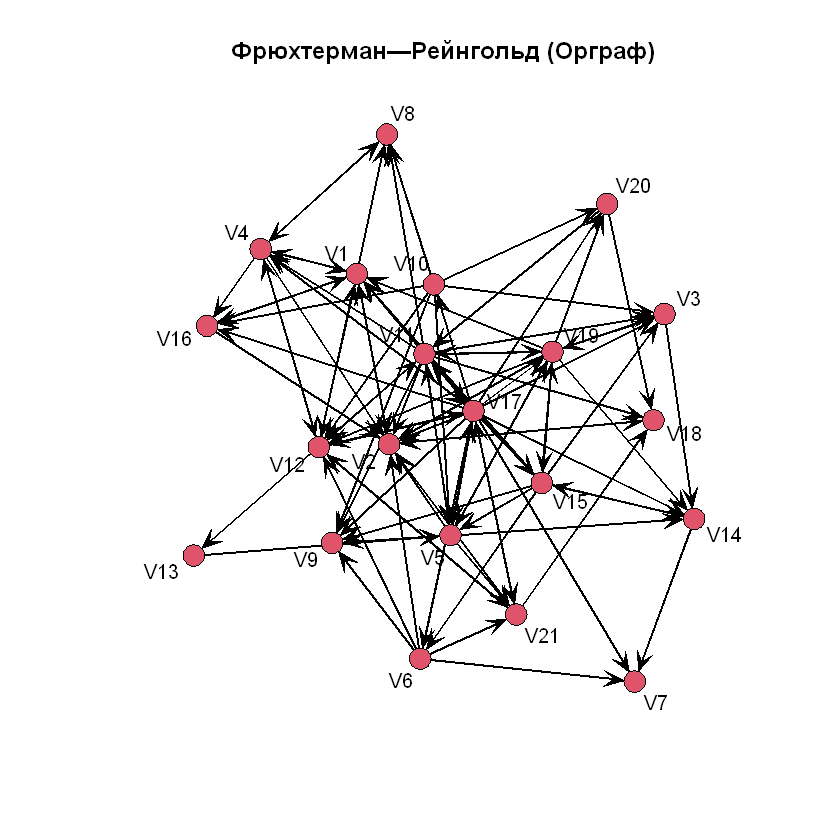

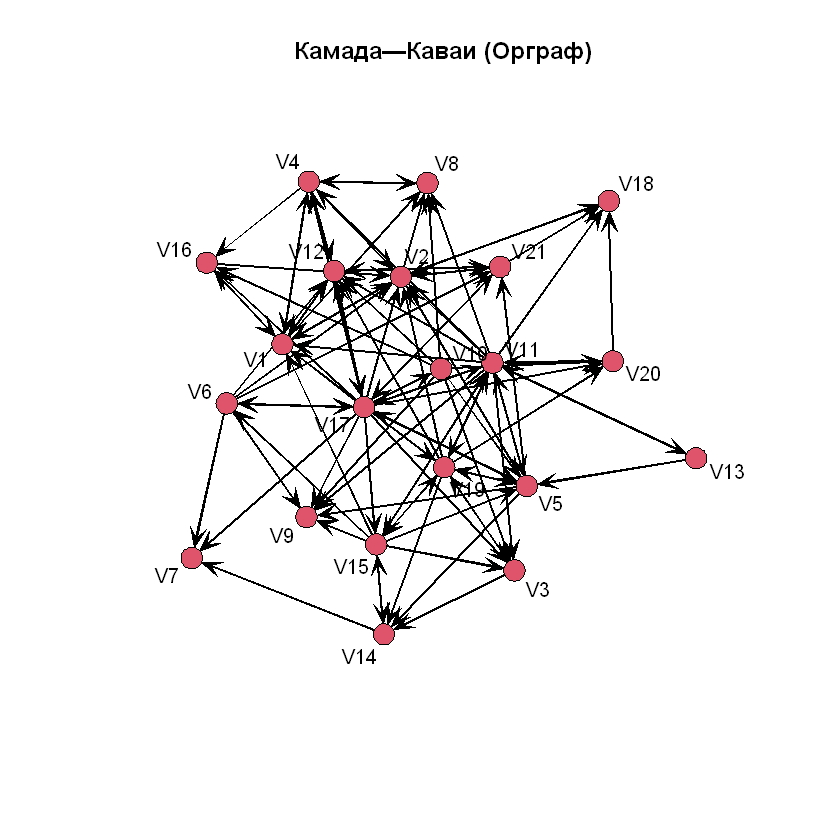

In [41]:
# Визуализация (п. 5)
# Используем gmode = "digraph" для направленного графа
gplot(net_2, gmode = "digraph", mode = "fruchtermanreingold", displaylabels = TRUE, main = "Фрюхтерман—Рейнгольд (Орграф)")

gplot(net_2, gmode = "digraph", mode = "kamadakawai", displaylabels = TRUE, main = "Камада—Каваи (Орграф)")

In [44]:
# Описательная сводка (п. 6)
cat("\n[Пункт 6] Описательная сводка:\n")
summary(net_2)


[Пункт 6] Описательная сводка:


Network attributes:
  vertices = 21
  directed = TRUE
  hyper = FALSE
  loops = FALSE
  multiple = FALSE
  bipartite = FALSE
 total edges = 102 
   missing edges = 0 
   non-missing edges = 102 
 density = 0.2428571 

Vertex attributes:
  vertex.names:
   character valued attribute
   21 valid vertex names

No edge attributes

Network edgelist matrix:
       [,1] [,2]
  [1,]    2    1
  [2,]    4    1
  [3,]   11    1
  [4,]   12    1
  [5,]   15    1
  [6,]   16    1
  [7,]   17    1
  [8,]   19    1
  [9,]    1    2
 [10,]    4    2
 [11,]    5    2
 [12,]    6    2
 [13,]   11    2
 [14,]   16    2
 [15,]   17    2
 [16,]   18    2
 [17,]   19    2
 [18,]   21    2
 [19,]   10    3
 [20,]   11    3
 [21,]   15    3
 [22,]   17    3
 [23,]   19    3
 [24,]    1    4
 [25,]    8    4
 [26,]   11    4
 [27,]   12    4
 [28,]   17    4
 [29,]   10    5
 [30,]   11    5
 [31,]   13    5
 [32,]   15    5
 [33,]   17    5
 [34,]   19    5
 [35,]   15    6
 [36,]   17    6
 [37,]    6    7


In [45]:
# Пятичисловая сводка (п. 7)
cat("\n[Пункт 7] Пятичисловая сводка:\n")

g2 <- network.size(net_2)
cat("(а) Размер сети:", g2, "\n")

# Плотность для орграфа считается как m / (n * (n - 1))
den_manual_2 <- sum(network_matrix_2 != 0) / (g2 * (g2 - 1))
den_prog_2   <- network.density(net_2)
cat("(b) Плотность (вручную):", den_manual_2, "\n")
cat("(b) Плотность (функция):", den_prog_2, "\n")

# Компоненты связности для направленного графа
ks_weak   <- sna::components(net_2, connected = "weak")
ks_strong <- sna::components(net_2, connected = "strong")
cat("(c) Слабых компонент:", ks_weak, "\n")
cat("(c) Сильных компонент:", ks_strong, "\n")

# Диаметр
g_dir <- graph_from_adjacency_matrix(network_matrix_2, mode = "directed")
wcomp <- components(g_dir, mode = "weak")
largest_w <- induced_subgraph(g_dir, which(wcomp$membership == which.max(wcomp$csize)))
diam_2 <- diameter(largest_w, directed = TRUE)
cat("(d) Диаметр (наибольшей слабой компоненты):", diam_2, "\n")

# Коэффициент кластеризации для орграфа
gtrans_2 <- sna::gtrans(net_2, mode = "digraph")
cat("(e) Глобальный коэффициент кластеризации:", gtrans_2, "\n")


[Пункт 7] Пятичисловая сводка:
(а) Размер сети: 21 
(b) Плотность (вручную): 0.2428571 
(b) Плотность (функция): 0.2428571 
(c) Слабых компонент: 1 
(c) Сильных компонент: 3 
(d) Диаметр (наибольшей слабой компоненты): 5 
(e) Глобальный коэффициент кластеризации: 0.4610526 


**Выводы по пятичисловой сводке (направленная сеть):**

*   **(b) Плотность:** Значения совпали и равны `0.243` (около 24.3%). Сеть дружеских связей плотнее, чем сеть брачных союзов (там было 16.7%), но всё ещё остается разреженной.
*   **(c) Компоненты связности:** Слабая компонента всего `1`, а сильных — `3`. Это означает, что если мы проигнорируем направление стрелок, то вся сеть представляет собой единое целое (все со всеми связаны). Однако, так как сильных компонент 3, внутри этой большой группы есть подгруппы, где дружба не всегда взаимна (кто-то дружит, но с ним не дружат в ответ, поэтому вернуться по тем же стрелкам невозможно).
*   **(d) Диаметр:** Диаметр равен `5`. Максимальное расстояние (по направлению стрелок) между двумя людьми в этой сети составляет 5 шагов.
*   **(e) Коэффициент кластеризации:** Глобальный коэффициент равен `0.461`. Это средний/умеренно высокий показатель, который говорит о том, что в компании менеджеров часто образуются «треугольники» (друзья друзей тоже дружат между собой).

**Задание 10.** Заполнить таблицу для различных мер престижа: $P_D(n_i)$, $P_P(n_i)$, $P_R(n_i)$.

Для направленной сети мы вычисляем престиж по степени (количество входящих связей), престиж по близости (насколько быстро до актора можно добраться от других) и престиж по рангу (влиятельность с учетом авторитетности тех, кто выбирает).

In [52]:
# Престиж по степени (Degree Prestige) - нормированный
prestige_degree <- prestige(net_2, cmode = "indegree")
prestige_degree_norm <- prestige_degree / (g2 - 1)

# Престиж по близости через igraph (насколько легко ДРУГИЕ достигают узла)
prestige_proximity <- closeness(g_dir, mode = "in", normalized = TRUE)

# Престиж по рангу (Rank Prestige / Eigenvector)
prestige_rank <- prestige(net_2, cmode = "eigenvector")
prestige_rank_norm <- prestige_rank / sum(prestige_rank)

# Таблица
prestige_table <- data.frame(P_D = round(prestige_degree_norm, 3), P_P = round(prestige_proximity, 3), P_R = round(prestige_rank_norm, 3))
print(prestige_table)

     P_D   P_P   P_R
V1  0.40 0.643 0.096
V2  0.50 0.667 0.104
V3  0.25 0.474 0.040
V4  0.25 0.529 0.067
V5  0.30 0.486 0.041
V6  0.10 0.400 0.020
V7  0.15 0.422 0.025
V8  0.25 0.529 0.055
V9  0.30 0.475 0.043
V10 0.05 0.360 0.012
V11 0.30 0.486 0.043
V12 0.40 0.600 0.080
V13 0.05 0.333 0.009
V14 0.25 0.462 0.045
V15 0.20 0.450 0.038
V16 0.20 0.486 0.047
V17 0.30 0.529 0.062
V18 0.20 0.514 0.046
V19 0.25 0.474 0.044
V20 0.15 0.429 0.023
V21 0.25 0.514 0.061


**Выводы по мерам престижа:**

*   **Престиж по степени (\(P_D\)):** Максимальные значения у акторов **V2** (0.50), **V1** (0.40) и **V12** (0.40). Это означает, что их выбрало (с ними дружат) наибольшее количество других менеджеров. Они являются самыми популярными в компании. Минимальный престиж у V10 и V13 (по 0.05).
*   **Престиж по близости (\(P_P\)):** Наивысшие показатели снова у **V2** (0.667), **V1** (0.643) и **V12** (0.600). Это значит, что до них очень легко «добраться» по направленным связям от других участников сети, они находятся в самом центре коммуникаций. Самый низкий показатель у V13 (0.333).
*   **Престиж по рангу (\(P_R\)):** Здесь также лидируют **V2** (0.104), **V1** (0.096) и **V12** (0.080). Этот показатель учитывает не только количество входящих связей, но и «авторитетность» тех, кто их выбирает. Высокое значение означает, что этих акторов выбирают люди, которые сами являются влиятельными в компании.

**Общий вывод по престижу:** В сети дружеских связей влияние распределено неравномерно. Есть явное ядро из трех менеджеров (V1, V2, V12), которые пользуются наибольшим авторитетом по всем трем метрикам. В то же время акторы V10 и V13 находятся на периферии, так как их почти никто не выбирает в качестве друзей.

**Задание 11.** Общий вывод по работе.

**Сравнение проанализированных сетей:**

*   **Ненаправленная сеть (брачные союзы Медичи)** оказалась сильно разреженной (16.7%) и несвязной, распадаясь на две компоненты. В ней ярко выражен один абсолютный лидер - семья **Medici**, которая имеет наивысшие показатели по всем мерам центральности (особенно по посредничеству), выступая главным связующим звеном (мостом) между остальными кланами.
*   **Направленная сеть (дружеские связи менеджеров)** является более плотной (24.3%) и кластеризованной (0.46). Несмотря на наличие трех сильных компонент (что говорит о невзаимности некоторых дружеских связей), она представляет собой единое слабо связное целое. Анализ мер престижа выявил явное ядро из трех акторов (**V1, V2, V12**), которые пользуются наибольшим авторитетом и популярностью среди коллег.

Таким образом, в ходе работы были успешно освоены инструменты сетевого анализа в R. Мы убедились, что математические метрики (центральность и престиж) позволяют объективно выявлять неформальных лидеров и структуру влияния в социальных группах, что имеет огромное значение для социологии, менеджмента и анализа данных.

## ВЫВОД
В ходе выполнения практической работы были проанализированы две социальные сети с использованием математического пакета R и библиотек `network`, `sna` и `igraph` в среде Jupyter Notebook. 

Были изучены и применены на практике следующие методы:
1. Извлечение социоматриц из файлов и преобразование их в списки рёбер.
2. Визуализация сетей с помощью алгоритмов укладки Фрюхтермана-Рейнгольда (ориентирован на локальные связи) и Камада—Каваи (учитывает кратчайшие пути).
3. Вычисление «пятичисловой сводки» (размер, плотность, компоненты связности, диаметр, кластеризация).
4. Расчет мер центральности для ненаправленной сети и мер престижа для направленной.